# Alignment report figures

This analysis regenerates the two Section 2 report figures from maintained artifacts: the three-seed alignment summary and three held-out EEG-to-image top-four retrieval panels. It uses the selected aligned-SynCLR + ATMS checkpoint and does not retrain a model.

Each retrieval row contains one ground-truth image followed by the four image latents with the highest cosine similarity to that EEG embedding. The score under every candidate is the normalized EEG-to-image dot product; the ground-truth target can appear at any rank.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image
from torch.nn import functional as F

from brain_image.data.data import get_from_batch
from brain_image.model.eeg_alignment import EEGAlignmentModel
from brain_image.model.encoder.eeg_encoder.eeg_encoder import batch_encode_eeg_latent
from brain_image.utils import gather_dataloader

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)

RUN_ROOT = PROJECT_ROOT / 'experiments/eeg_alignment_sweep/20260830_231325_task4/train_eeg-20260830_231357/version_0'
CHECKPOINT_PATH = RUN_ROOT / 'checkpoints/epoch_0089-val_align_top1_0.7650.ckpt'
SWEEP_RESULTS_PATH = PROJECT_ROOT / 'experiments/eeg_alignment_sweep/aggregated_metrics.csv'
REPORT_IMAGES = PROJECT_ROOT / 'report/69bd47171c8bd99594e793c6/images'
REPORT_IMAGES.mkdir(exist_ok=True)

assert CHECKPOINT_PATH.exists(), CHECKPOINT_PATH
assert SWEEP_RESULTS_PATH.exists(), SWEEP_RESULTS_PATH

/home/gasparyanartur/dev/brain-image-implementation/.venv/lib/python3.12/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/gasparyanartur/dev/brain-image-implementation/.venv/lib/python3.12/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadat

/home/gasparyanartur/dev/brain-image-implementation/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


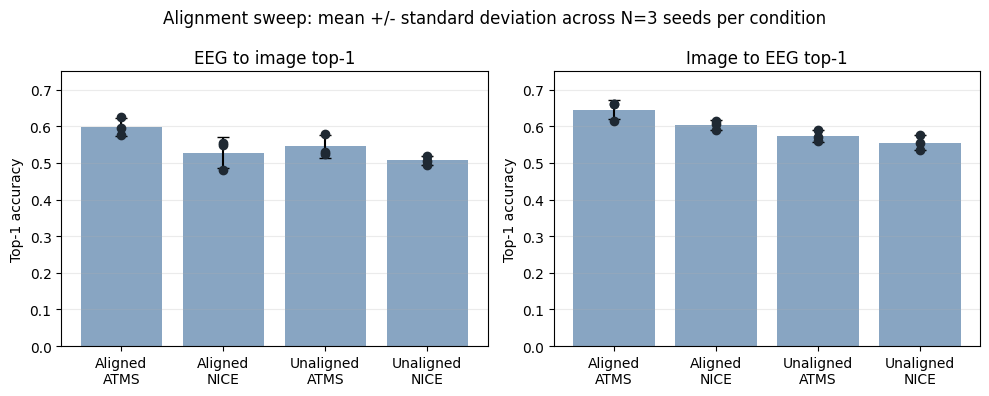

image_acc           brain_acc          
                                     mean       std      mean       std
target                  encoder                                        
aligned_synclr_vitb16   atms     0.598333  0.025166  0.645000  0.025981
                        nice     0.528333  0.041932  0.603333  0.012583
unaligned_synclr_vitb16 atms     0.545000  0.030414  0.573333  0.015275
                        nice     0.506667  0.012583  0.555000  0.020000

In [2]:
results = pd.read_csv(SWEEP_RESULTS_PATH).rename(columns={
    'eval/test/align/image_acc': 'image_acc',
    'eval/test/align/brain_acc': 'brain_acc',
    'model.align_img_encoder': 'target',
    'model.eeg_encoder.eeg_encoder': 'encoder',
    'model.seed': 'seed',
})
results['image_acc'] = pd.to_numeric(results['image_acc'])
results['brain_acc'] = pd.to_numeric(results['brain_acc'])
results['seed'] = results['seed'].astype(int)
assert len(results) == 12

condition_order = [
    ('aligned_synclr_vitb16', 'atms'),
    ('aligned_synclr_vitb16', 'nice'),
    ('unaligned_synclr_vitb16', 'atms'),
    ('unaligned_synclr_vitb16', 'nice'),
]
condition_labels = ['Aligned\nATMS', 'Aligned\nNICE', 'Unaligned\nATMS', 'Unaligned\nNICE']
summary = (results.groupby(['target', 'encoder'])[['image_acc', 'brain_acc']]
           .agg(['mean', 'std'])
           .reindex(condition_order))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
for axis, metric, title in zip(axes, ['image_acc', 'brain_acc'], ['EEG to image top-1', 'Image to EEG top-1']):
    means = summary[(metric, 'mean')].to_numpy()
    stds = summary[(metric, 'std')].to_numpy()
    positions = range(len(condition_order))
    axis.bar(positions, means, yerr=stds, capsize=4, color='#6b8fb3', alpha=0.8)
    for position, condition in enumerate(condition_order):
        values = results[(results.target == condition[0]) & (results.encoder == condition[1])][metric]
        axis.scatter([position] * len(values), values, color='#1f2933', zorder=3)
    axis.set_xticks(list(positions), condition_labels)
    axis.set_ylim(0.0, 0.75)
    axis.set_title(title)
    axis.set_ylabel('Top-1 accuracy')
    axis.grid(axis='y', alpha=0.25)
fig.suptitle('Alignment sweep: mean +/- standard deviation across N=3 seeds per condition')
fig.tight_layout()
seed_plot_path = REPORT_IMAGES / 'alignment_seed_summary.png'
fig.savefig(seed_plot_path, dpi=220, bbox_inches='tight')
plt.show()
summary

INFO: Seed set to 42


INFO:lightning.fabric.utilities.seed:Seed set to 42


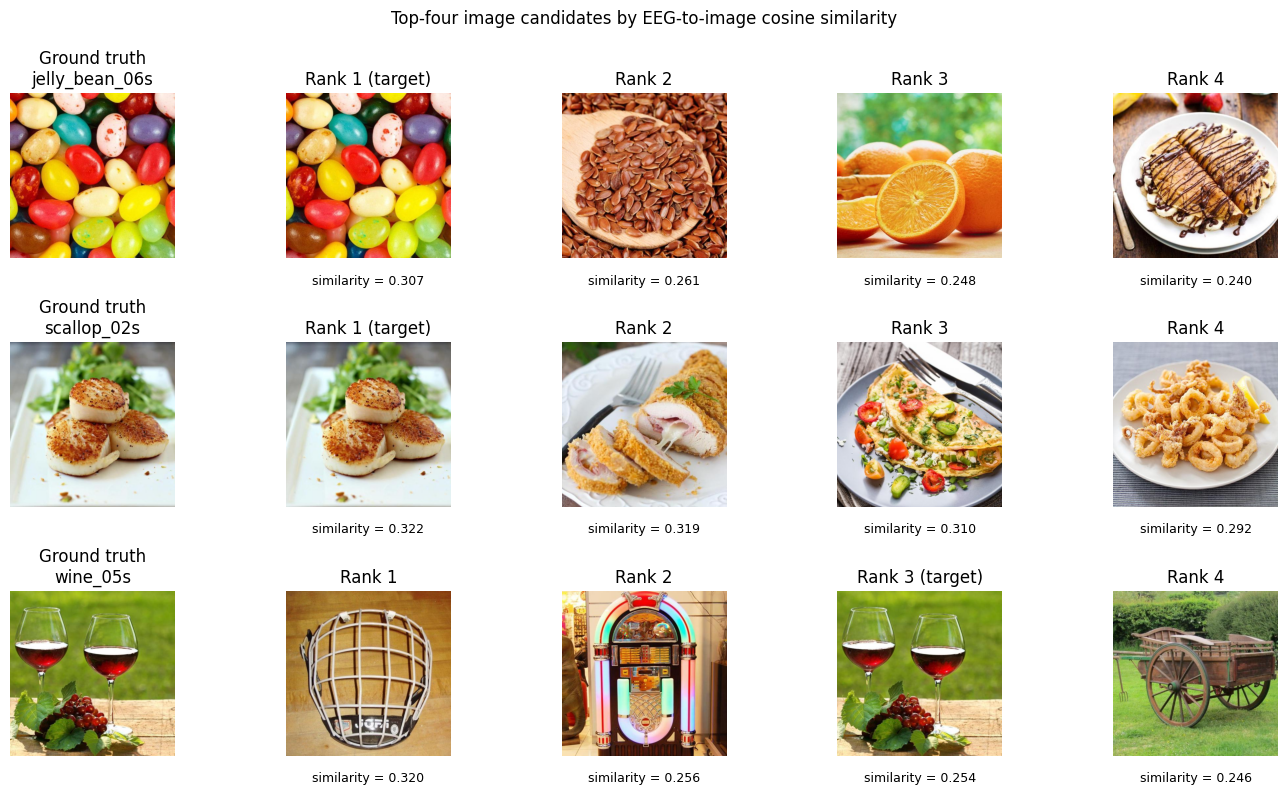

PosixPath('/home/gasparyanartur/dev/brain-image-implementation/report/69bd47171c8bd99594e793c6/images/alignment_top4_retrievals.png')

In [3]:
model = EEGAlignmentModel.load_from_checkpoint(CHECKPOINT_PATH).eval().cuda()
model.config.do_recon = False
data_loader = model.data_module.get_dataloader('test')
all_data = gather_dataloader(data_loader)

eeg = get_from_batch('eeg_data', all_data, torch.Tensor)
sub = get_from_batch('sub', all_data, torch.Tensor)
with torch.inference_mode():
    eeg_outputs = batch_encode_eeg_latent(
        model.eeg_encoder, eeg, sub,
        batch_size=model.data_module.config.get_batch_size('test'),
        progress_bar=False,
    )

eeg_embeddings = get_from_batch('eeg_latent_normed', eeg_outputs, torch.Tensor).cuda()
image_embeddings = get_from_batch('align_img_latent', all_data, torch.Tensor).cuda()
image_paths = [Path(path) for path in get_from_batch('img_path', all_data, list)]
similarities = F.normalize(eeg_embeddings, dim=-1) @ F.normalize(image_embeddings, dim=-1).T

example_names = ['jelly_bean_06s', 'scallop_02s', 'wine_05s']
example_indices = []
for name in example_names:
    matches = [index for index, path in enumerate(image_paths) if path.stem == name]
    assert len(matches) == 1, (name, matches)
    example_indices.append(matches[0])

top_k = 4
fig, axes = plt.subplots(len(example_indices), top_k + 1, figsize=(14, 8), squeeze=False)
for row, target_index in enumerate(example_indices):
    target_path = image_paths[target_index]
    target_axis = axes[row, 0]
    target_axis.imshow(Image.open(target_path).convert('RGB'))
    target_axis.set_title(f'Ground truth\n{target_path.stem}')
    target_axis.axis('off')

    scores, candidate_indices = torch.topk(similarities[target_index], k=top_k)
    for rank, (score, candidate_index) in enumerate(zip(scores.cpu().tolist(), candidate_indices.cpu().tolist()), start=1):
        candidate_path = image_paths[candidate_index]
        axis = axes[row, rank]
        axis.imshow(Image.open(candidate_path).convert('RGB'))
        target_marker = ' (target)' if candidate_index == target_index else ''
        axis.set_title(f'Rank {rank}{target_marker}')
        axis.set_xticks([])
        axis.set_yticks([])
        for spine in axis.spines.values():
            spine.set_visible(False)
        axis.text(0.5, -0.10, f'similarity = {score:.3f}', ha='center', va='top', transform=axis.transAxes, fontsize=9, clip_on=False)

fig.suptitle('Top-four image candidates by EEG-to-image cosine similarity', y=0.99)
fig.tight_layout(h_pad=2.2)
top_four_path = REPORT_IMAGES / 'alignment_top4_retrievals.png'
fig.savefig(top_four_path, dpi=220, bbox_inches='tight')
plt.show()
top_four_path